> **DEPRECATED:** This task is outdated and may not reflect current best practices.
> See `causalab/tasks/MCQA/` for an up-to-date example.
>
> This notebook was updated to the current causalab API (plain lists of `CounterfactualExample`,
> `filter_dataset`, `build_attention_head_targets`, `run_interchange_interventions` and
> `train_DBM_binary_heatmaps`). The old `CounterfactualDataset`, `FilterExperiment`,
> `PatchAttentionHeads` and `compute_custom_scores` no longer exist.

# IOI (Indirect Object Identification) Task Demo

This notebook demonstrates the IOI task with causal abstraction analysis.

In [1]:
%load_ext autoreload
%autoreload 2

from causalab.tasks.IOI.causal_models import create_ioi_causal_model
from causalab.tasks.IOI.counterfactuals import (
    sample_well_formed_input,
    swap_names,
    flip_name_C,
    flip_name_C_sample_new_IO,
    swap_names_and_flip_C,
    random_counterfactual,
    random_ABC
)
from causalab.causal.causal_viz import print_structure


## Load the Causal Model

The IOI causal model generates prompts where two names (name_A and name_B) are mentioned, then a third name (name_C) that matches one of them appears before "gave a/an [object] to". The model should predict the other name.

The model includes:
- **Input variables**: template, name_A, name_B, name_C, place, object
- **Intermediate variables**: output_position (0 for A, 1 for B), output_token, logits
- **Output**: raw_input (the prompt) and raw_output (dict with token and logits)

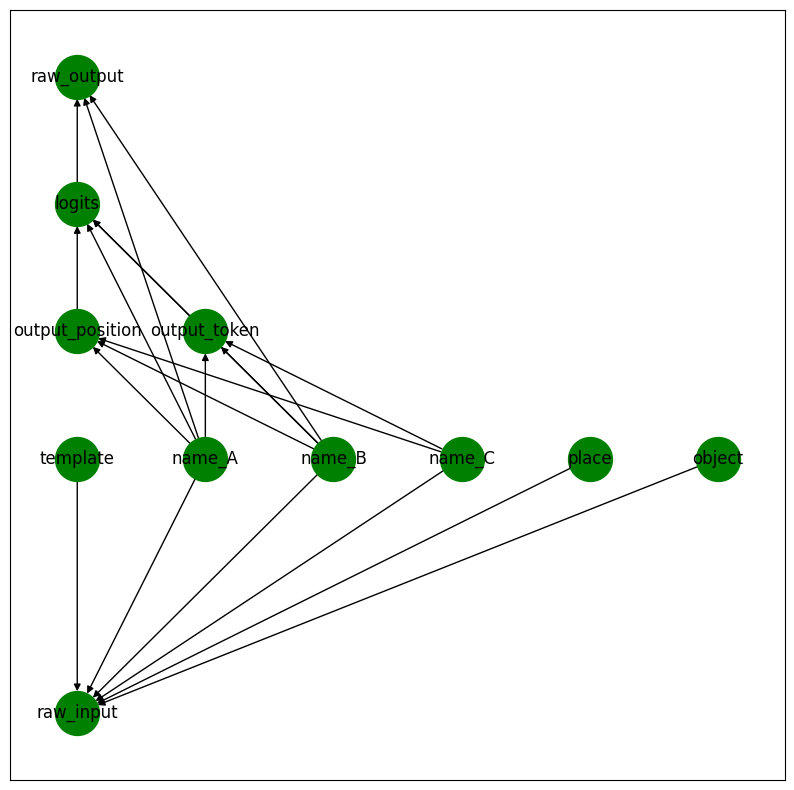

In [2]:
# Create the causal model with default parameters
causal_model = create_ioi_causal_model()

# Print the structure
print_structure(causal_model)

## Sample and Run an Input

In [3]:
# Sample a well-formed input
example = sample_well_formed_input()

print("Input variables:")
print(f"name_A: {example['name_A']}")
print(f"name_B: {example['name_B']}")
print(f"name_C: {example['name_C']}")
print(f"place: {example['place']}")
print(f"object: {example['object']}")
print(f"\nPrompt:\n{example['raw_input']}")

Input variables:
name_A: Kenneth
name_B: Erin
name_C: Kenneth
place: house
object: drink

Prompt:
Kenneth and Erin were working at the house. Then, Kenneth decided to give an drink to


In [4]:
# Run the causal model forward to get all variables
# sample_well_formed_input already returns the full CausalTrace
full_setting = example

print("\nCausal model outputs:")
print(f"output_position: {full_setting['output_position']} (0=A correct, 1=B correct)")
print(f"output_token: {full_setting['output_token']}")
print(f"logits: {full_setting['logits']}")
print(f"raw_output: {full_setting['raw_output']}")


Causal model outputs:
output_position: 1 (0=A correct, 1=B correct)
output_token: Erin
logits: {'Kenneth': 2.0, 'Erin': 4.0}
raw_output: {'string': ' Erin', 'logits': {'Kenneth': 2.0, 'Erin': 4.0}}


## Interchange Interventions on the Causal Model

Interchange interventions fix a variable to the value it would have in a counterfactual input.

In [5]:
# Generate counterfactual datasets: a dataset is a plain list of examples
size = 128

generators = {
    "swap_names": swap_names,
    "flip_name_C": flip_name_C,
    "flip_name_C_sample_new_IO": flip_name_C_sample_new_IO,
    "swap_names_and_flip_C": swap_names_and_flip_C,
    "random_counterfactual": random_counterfactual,
    "random_ABC": random_ABC,
}
datasets = {name: [gen() for _ in range(size)] for name, gen in generators.items()}

print(f"Generated {len(datasets)} datasets with {size} examples each")
print(f"Dataset names: {list(datasets.keys())}")

# Look at the flip_name_C dataset
flip_C_dataset = datasets["flip_name_C"]
print(f"\nFlip name_C dataset has {len(flip_C_dataset)} examples")

# Show one example from the dataset (both sides are CausalTraces)
example_pair = flip_C_dataset[0]
original = example_pair["input"]
counterfactual = example_pair["counterfactual_inputs"][0]

print("\nExample from flip_name_C dataset:")
print(
    f"Original: name_A={original['name_A']}, name_B={original['name_B']}, name_C={original['name_C']}"
)
print(f"  Prompt: {original['raw_input'][:80]}...")
print(f"  Output: {original['raw_output']}")

print(
    f"\nCounterfactual: name_A={counterfactual['name_A']}, name_B={counterfactual['name_B']}, name_C={counterfactual['name_C']}"
)
print(f"  Prompt: {counterfactual['raw_input'][:80]}...")
print(f"  Output: {counterfactual['raw_output']}")


Generated 6 datasets with 128 examples each
Dataset names: ['swap_names', 'flip_name_C', 'flip_name_C_sample_new_IO', 'swap_names_and_flip_C', 'random_counterfactual', 'random_ABC']

Flip name_C dataset has 128 examples

Example from flip_name_C dataset:
Original: name_A=David, name_B=Cody, name_C=David
  Prompt: While David and Cody were commuting to the station, David gave an basketball to...
  Output: {'string': ' Cody', 'logits': {'David': 2.0, 'Cody': 4.0}}

Counterfactual: name_A=David, name_B=Cody, name_C=Cody
  Prompt: While David and Cody were commuting to the station, Cody gave an basketball to...
  Output: {'string': ' David', 'logits': {'David': 4.0, 'Cody': 2.0}}


## Load GPT-2 Small and Test Performance

In [6]:
from causalab.neural.pipeline import LMPipeline
from transformers import GPT2Config
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
model_path = "openai-community/gpt2"

# Load GPT2 config
gpt_config = GPT2Config.from_pretrained(model_path)

# Create pipeline with position_ids=True
pipeline = LMPipeline(
    model_path,
    max_new_tokens=1,
    device=device,
    max_length=128,
    config=gpt_config,
    position_ids=True,
)


def checker(neural_output, causal_output):
    """Check if the model output matches the causal model prediction."""
    predicted_token = causal_output["string"].strip()
    return (
        predicted_token in neural_output["string"]
        or neural_output["string"] in predicted_token
    )


print(f"Model loaded on device: {device}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Model loaded on device: cuda


## Filter Datasets Based on Model Performance

In [7]:
from causalab.experiments.filter import filter_dataset

# Keep only examples where GPT-2 agrees with the causal model on the base
# and on the counterfactual inputs
print("Filtering datasets based on GPT-2 performance...")
filtered_datasets = {}
for name, dataset in datasets.items():
    if name == "random_ABC":
        continue  # the ABC counterfactuals have no correct answer, so we do not filter them
    filtered_datasets[name] = filter_dataset(
        dataset=dataset,
        pipeline=pipeline,
        causal_model=causal_model,
        metric=checker,
        batch_size=64,
    )
    kept = len(filtered_datasets[name])
    print(f"Dataset '{name}': kept {kept}/{len(dataset)} examples ({kept / len(dataset):.1%})")

# Add random_ABC back without filtering
filtered_datasets["random_ABC"] = datasets["random_ABC"]

print("\nFiltered datasets:")
for name, dataset in filtered_datasets.items():
    print(f"  {name}: {len(dataset)} examples")


Filtering datasets based on GPT-2 performance...


Dataset 'swap_names': kept 92/128 examples (71.9%)


Dataset 'flip_name_C': kept 95/128 examples (74.2%)


Dataset 'flip_name_C_sample_new_IO': kept 88/128 examples (68.8%)


Dataset 'swap_names_and_flip_C': kept 100/128 examples (78.1%)


Dataset 'random_counterfactual': kept 89/128 examples (69.5%)

Filtered datasets:
  swap_names: 92 examples
  flip_name_C: 95 examples
  flip_name_C_sample_new_IO: 88 examples
  swap_names_and_flip_C: 100 examples
  random_counterfactual: 89 examples
  random_ABC: 128 examples


In [8]:
# ============================================================================
# Attention Head Patching
# ============================================================================

from tqdm.auto import tqdm
from causalab.experiments.interchange_targets import build_attention_head_targets
from causalab.neural.token_position_builder import TokenPosition, get_last_token_index
from causalab.neural.pyvene_core.interchange import run_interchange_interventions

results_dir = "results/demo/"
num_heads = pipeline.get_num_attention_heads()
num_layers = pipeline.get_num_layers()

# Token position for the last token (where the next name is predicted)
last_token = TokenPosition(
    lambda x: get_last_token_index(x, pipeline), pipeline, id="last_token"
)

# One target per (layer, head): each head is patched on its own
head_targets = build_attention_head_targets(
    pipeline=pipeline,
    layers=list(range(num_layers)),
    heads=list(range(num_heads)),
    token_position=last_token,
    mode="one_target_per_unit",
)

abc_dataset = filtered_datasets["random_ABC"]

print(f"Running attention head patching on {len(head_targets)} heads...")
raw_results = {}
for key, target in tqdm(head_targets.items(), desc="Running interventions"):
    # output_scores=True keeps the full next-token logits, needed for the logit difference
    raw_results[key] = run_interchange_interventions(
        pipeline=pipeline,
        counterfactual_dataset=abc_dataset,
        interchange_target=target,
        batch_size=64,
        output_scores=True,
    )

print("Raw interventions completed!")


Running attention head patching on 144 heads...


Running interventions:   0%|          | 0/144 [00:00<?, ?it/s]

Raw interventions completed!


Mean logit difference without intervention: 2.71


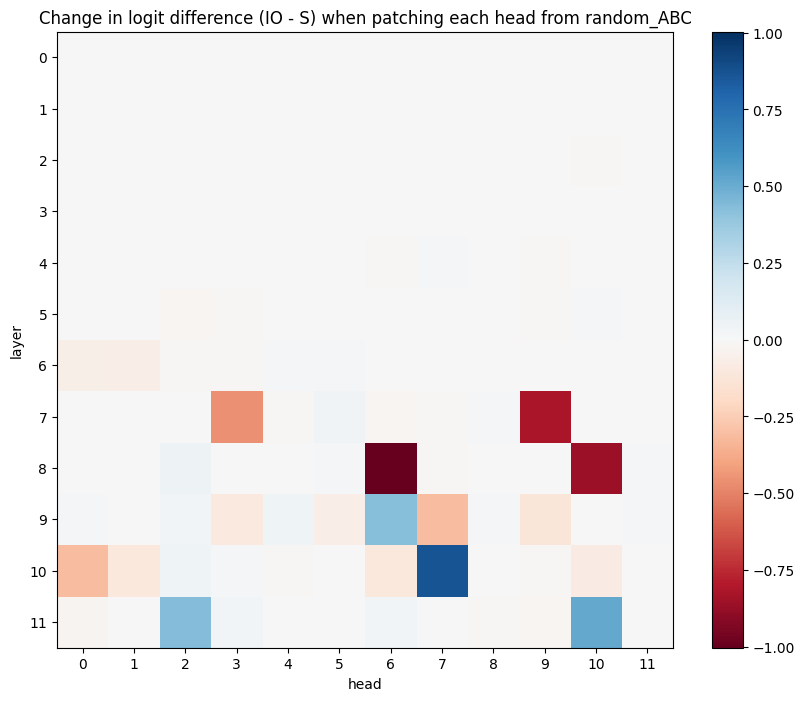

Heads whose patching lowers the logit difference the most:
  layer 8, head 6: -1.00
  layer 8, head 10: -0.86
  layer 7, head 9: -0.82
  layer 7, head 3: -0.46
  layer 9, head 7: -0.31


In [9]:
# ============================================================================
# Logit Difference Visualization
# ============================================================================

import numpy as np
import torch
import matplotlib.pyplot as plt


def name_token_id(name):
    # GPT-2 predicts the name with a leading space (" Mary"), so encode it that way
    return pipeline.tokenizer.encode(" " + name.strip(), add_special_tokens=False)[0]


def correct_and_incorrect_ids(base):
    """Token ids of the indirect object (correct) and the subject (incorrect)."""
    correct = base["raw_output"]["string"].strip()
    incorrect = next(n for n in base["raw_output"]["logits"] if n.strip() != correct)
    return name_token_id(correct), name_token_id(incorrect)


ids = torch.tensor([correct_and_incorrect_ids(ex["input"]) for ex in abc_dataset])  # (N, 2)

# Logits without any intervention
with torch.no_grad():
    batch = pipeline.load([ex["input"] for ex in abc_dataset])
    actual_logits = pipeline.model(**batch).logits[:, -1, :].float().cpu()  # (N, vocab)
rows = torch.arange(len(abc_dataset))
actual_diff = actual_logits[rows, ids[:, 0]] - actual_logits[rows, ids[:, 1]]  # (N,)

# For each head: mean over examples of logit_diff[intervention] - logit_diff[actual]
logit_diff_scores = np.zeros((num_layers, num_heads))
for (layer, head), output in raw_results.items():
    # output["scores"]: one entry per batch, each a list with one (batch, vocab) tensor
    intervened_logits = torch.cat([steps[0] for steps in output["scores"]]).float()
    intervened_diff = intervened_logits[rows, ids[:, 0]] - intervened_logits[rows, ids[:, 1]]
    logit_diff_scores[layer, head] = (intervened_diff - actual_diff).mean().item()

print(f"Mean logit difference without intervention: {actual_diff.mean():.2f}")

vmax = np.abs(logit_diff_scores).max()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(logit_diff_scores, cmap="RdBu", vmin=-vmax, vmax=vmax)
ax.set_xlabel("head")
ax.set_ylabel("layer")
ax.set_xticks(range(num_heads))
ax.set_yticks(range(num_layers))
ax.set_title("Change in logit difference (IO - S) when patching each head from random_ABC")
fig.colorbar(im, ax=ax)
plt.show()

top = np.dstack(np.unravel_index(np.argsort(logit_diff_scores.ravel()), logit_diff_scores.shape))[0]
print("Heads whose patching lowers the logit difference the most:")
for layer, head in top[:5]:
    print(f"  layer {layer}, head {head}: {logit_diff_scores[layer, head]:+.2f}")


## Name-Mover Heads

Use Desiderata-Based Masking (DBM) to learn which attention heads carry the output_token variable.

Training DBM to localize the heads that carry the output name...


Training targets:   0%|          | 0/1 [00:00<?, ?it/s]

Training InterchangeTarget(1 groups, 144 total units)...:   0%|          | 0/24 [00:00<?, ?it/s]

Epoch: 0:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0:   0%|          | 0/3 [00:04<?, ?it/s, loss=8.44, accuracy=0.09, token_accuracy=0.09]

Epoch: 0:  33%|███▎      | 1/3 [00:05<00:10,  5.34s/it, loss=8.44, accuracy=0.09, token_accuracy=0.09]

... (216 outputs left out)

Processing batches:   0%|          | 0/1 [00:00<?, ?it/s]

Processing batches: 100%|██████████| 1/1 [00:02<00:00,  2.61s/it]

Training targets: 100%|██████████| 1/1 [04:41<00:00, 281.58s/it]

Training targets: 100%|██████████| 1/1 [04:41<00:00, 281.58s/it]

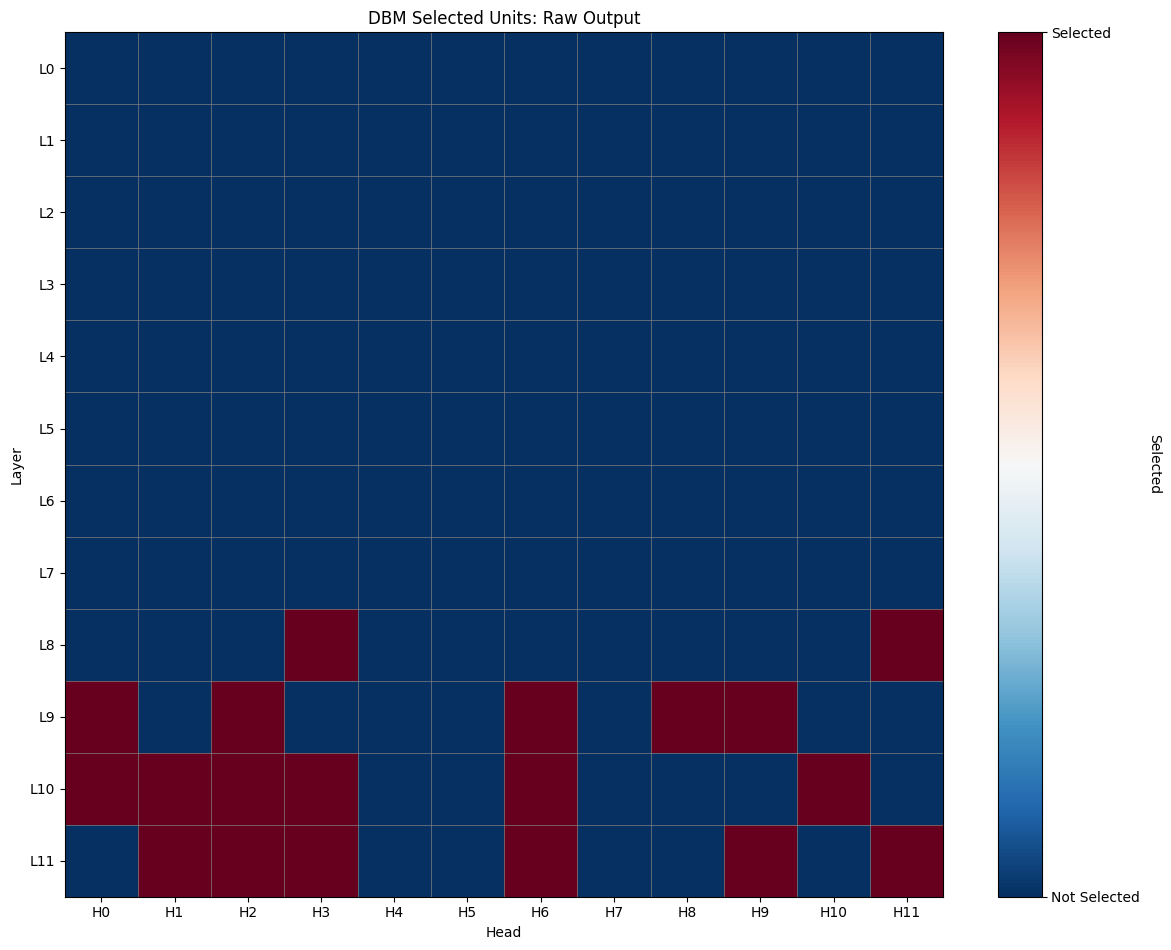

Training and evaluation complete!


In [10]:
# ============================================================================
# DBM Training to Find Name-Mover Heads
# ============================================================================

import os
from causalab.causal.causal_utils import save_counterfactual_examples
from causalab.experiments.jobs.DBM_binary_grid import train_DBM_binary_heatmaps


def save_train_test(name, dataset, train_fraction=0.8):
    """Split a dataset and save both halves as JSON for the training jobs."""
    split = int(len(dataset) * train_fraction)
    paths = {}
    for part, examples in [("train", dataset[:split]), ("test", dataset[split:])]:
        paths[part] = os.path.join(results_dir, "datasets", name, f"{part}.json")
        os.makedirs(os.path.dirname(paths[part]), exist_ok=True)
        save_counterfactual_examples(examples, paths[part])
    return paths


dbm_config = {
    "train_batch_size": 32,
    "evaluation_batch_size": 64,
    "training_epoch": 24,
    "init_lr": 0.001,
    # 10 instead of the original 0.1: with 0.1 the mask keeps 83 of 144 heads;
    # with 10 it keeps ~20 at the same IIA, which actually localizes the heads
    "masking": {"regularization_coefficient": 10.0},
    "featurizer_kwargs": {"tie_masks": True},
}

# A single target with all heads at the last token: DBM learns which ones to keep
all_heads_target = build_attention_head_targets(
    pipeline=pipeline,
    layers=list(range(num_layers)),
    heads=list(range(num_heads)),
    token_position=last_token,
    mode="one_target_all_units",
)[("all",)]

paths = save_train_test("random_counterfactual", filtered_datasets["random_counterfactual"])

print("Training DBM to localize the heads that carry the output name...")
name_mover_result = train_DBM_binary_heatmaps(
    causal_model=causal_model,
    interchange_target=all_heads_target,
    train_dataset_path=paths["train"],
    test_dataset_path=paths["test"],
    pipeline=pipeline,
    target_variable_group=("raw_output",),
    output_dir=os.path.join(results_dir, "dbm_name_movers"),
    metric=checker,
    config=dbm_config,
    tie_masks=True,
    verbose=True,
)
print("Training and evaluation complete!")


Train IIA: 0.986
Test IIA:  1.000
Selected heads (19): [(8, 3), (8, 11), (9, 0), (9, 2), (9, 6), (9, 8), (9, 9), (10, 0), (10, 1), (10, 2), (10, 3), (10, 6), (10, 10), (11, 1), (11, 2), (11, 3), (11, 6), (11, 9), (11, 11)]


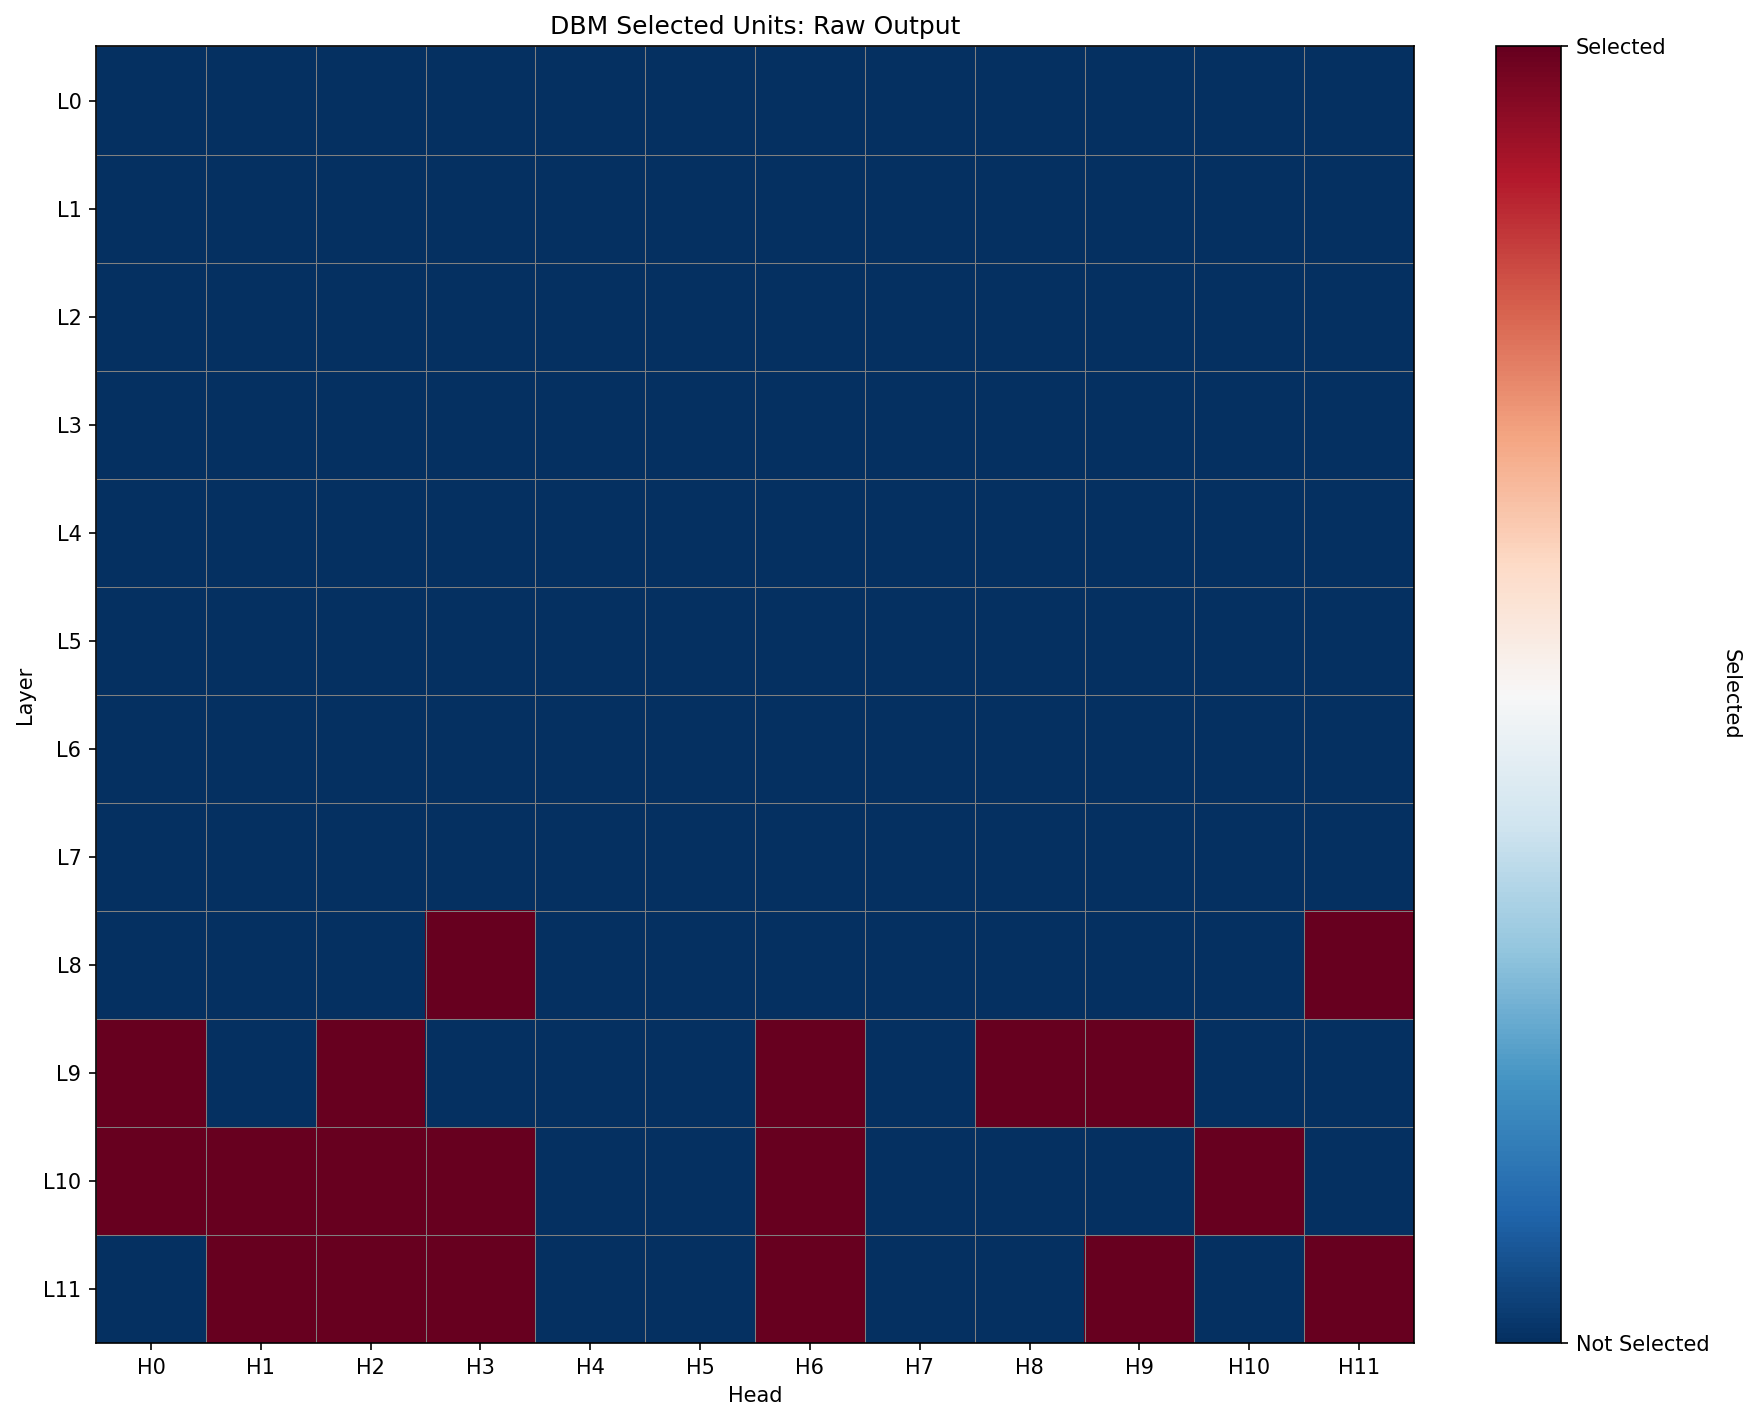

In [11]:
from IPython.display import Image, display

print(f"Train IIA: {name_mover_result['train_score']:.3f}")
print(f"Test IIA:  {name_mover_result['test_score']:.3f}")
print(f"Selected heads ({len(name_mover_result['selected_units'])}): {name_mover_result['selected_units']}")

# Mask heatmap saved by the job
display(Image(filename=name_mover_result["output_paths"]["mask_heatmap"]))


**Reading the result.** The selected heads sit in layers 8–11, at the last token, and include 9.6, 9.9 and 10.0, the *name mover* heads described by [Wang et al. (2023)](https://arxiv.org/abs/2211.00593), which copy the indirect object's name to the output. With the original regularization (0.1) the mask kept 83 of the 144 heads at the same IIA, which says little about localization; the stronger penalty is what makes the result interpretable.

# Negative Name Mover Heads

In [12]:
example = filtered_datasets["flip_name_C_sample_new_IO"][0]
print("Original Input:")
print(example["input"]["raw_input"])
print("Counterfactual Input:")
print(example["counterfactual_inputs"][0]["raw_input"])
causal_model.can_distinguish_with_dataset(
    filtered_datasets["flip_name_C_sample_new_IO"],
    ["output_position", "output_token"],
    ["raw_output"],
)

Original Input:
Later, Katherine and Erica met at the store. Katherine bought an kiss for
Counterfactual Input:
Later, Sarah and Erica met at the store. Erica bought an kiss for


{'proportion': 1.0, 'count': 88}

Training DBM to localize heads carrying both output_position and output_token...


Training targets:   0%|          | 0/1 [00:00<?, ?it/s]

Training InterchangeTarget(1 groups, 144 total units)...:   0%|          | 0/12 [00:00<?, ?it/s]

Epoch: 0:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0:   0%|          | 0/3 [00:04<?, ?it/s, loss=9.09, accuracy=0, token_accuracy=0]

Epoch: 0:  33%|███▎      | 1/3 [00:05<00:10,  5.22s/it, loss=9.09, accuracy=0, token_accuracy=0]

... (108 outputs left out)

Processing batches:   0%|          | 0/1 [00:00<?, ?it/s]

Processing batches: 100%|██████████| 1/1 [00:02<00:00,  2.61s/it]

Training targets: 100%|██████████| 1/1 [02:27<00:00, 147.07s/it]

Training targets: 100%|██████████| 1/1 [02:27<00:00, 147.08s/it]

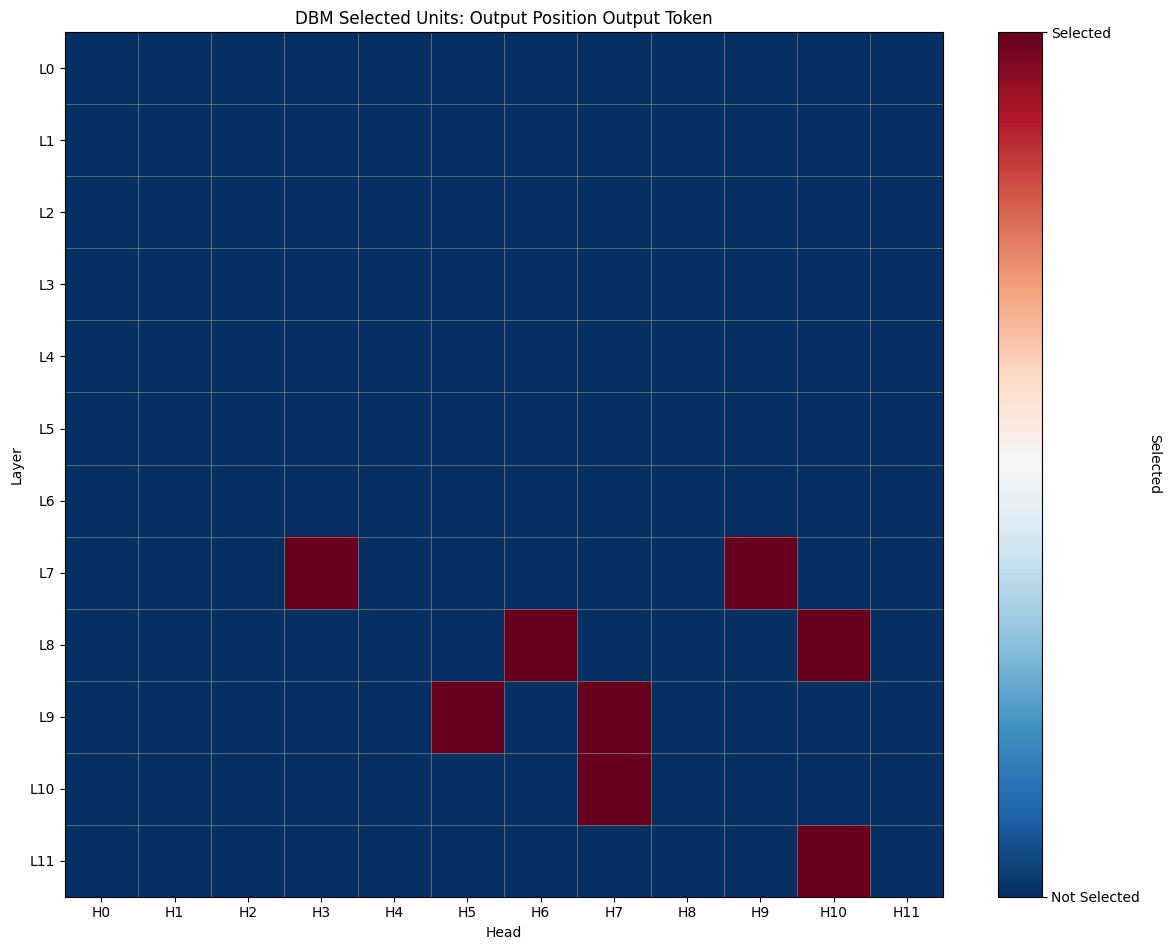

Training and evaluation complete!


In [13]:
# ============================================================================
# Negative Name Mover Heads
# ============================================================================

negative_config = {**dbm_config, "training_epoch": 12}

paths = save_train_test("flip_name_C_sample_new_IO", filtered_datasets["flip_name_C_sample_new_IO"])

print("Training DBM to localize heads carrying both output_position and output_token...")
negative_result = train_DBM_binary_heatmaps(
    causal_model=causal_model,
    interchange_target=all_heads_target,
    train_dataset_path=paths["train"],
    test_dataset_path=paths["test"],
    pipeline=pipeline,
    target_variable_group=("output_position", "output_token"),
    output_dir=os.path.join(results_dir, "dbm_negative_name_movers"),
    metric=checker,
    config=negative_config,
    tie_masks=True,
    verbose=True,
)
print("Training and evaluation complete!")


Train IIA: 1.000
Test IIA:  1.000
Selected heads (8): [(7, 3), (7, 9), (8, 6), (8, 10), (9, 5), (9, 7), (10, 7), (11, 10)]


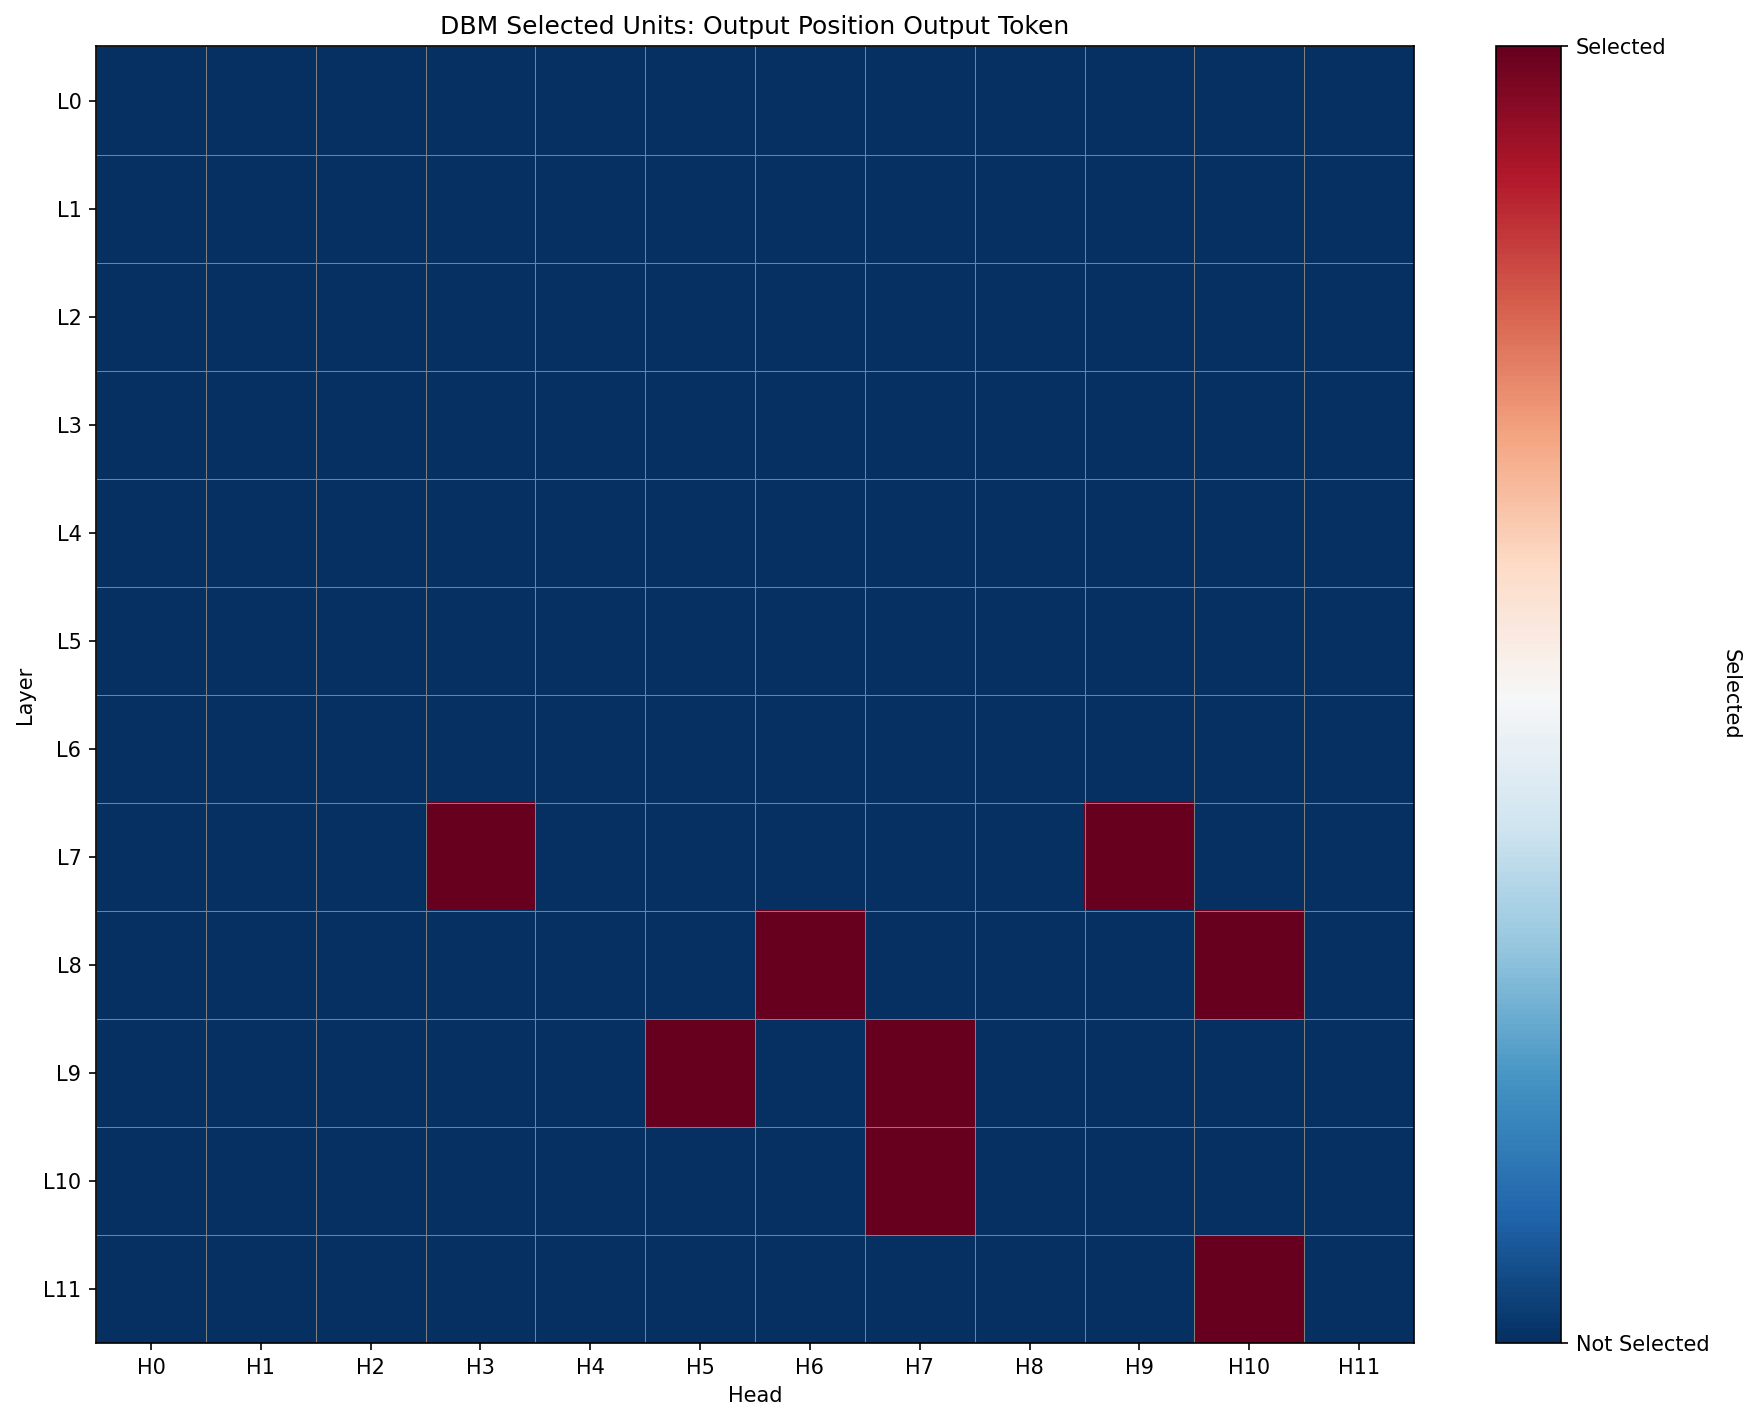

In [14]:
print(f"Train IIA: {negative_result['train_score']:.3f}")
print(f"Test IIA:  {negative_result['test_score']:.3f}")
print(f"Selected heads ({len(negative_result['selected_units'])}): {negative_result['selected_units']}")

display(Image(filename=negative_result["output_paths"]["mask_heatmap"]))


**Reading the result.** With a strong sparsity penalty the mask keeps only a handful of heads. In this run they include 7.3, 7.9, 8.6 and 8.10, which are the *S-inhibition* heads of [Wang et al. (2023)](https://arxiv.org/abs/2211.00593) (the same heads that the logit-difference patching above ranked highest), together with 10.7 and 11.10, which that paper identifies as *negative name mover* heads. Intervening on `output_position` and `output_token` jointly therefore finds both the heads that decide *which* name to inhibit and the heads that write against the indirect object.